# Projeto 2 - Small Caps de valor - A estratégia deo Buffet realmente funciona?


### Desafio:

* Testar se a regra de investimento de investimento em small caps de valor funciona no Brasil.


### Passo a passo:

   **Passo 1** - Importar os módulos e bibliotecas.
   
   **Passo 2** - Baixar os dados disponibilizados.
   
   **Passo 3** - Calcular a rentabilidade mensal das empresas. 
   
   **Passo 4** - Filtrar  a liquidez.
   
   **Passo 5** - Criar o ranking do indicador.
   
   **Passo 6** - Criar as carteiras. 
   
   **Passo 7** - Calcular a rentabilidade por carteira.
   
   **Passo 8** - Calcular a rentabilidade do modelo.

   **Passo 9** - Calcular a rentabilidade do ibovespa no mesmo período.

   **Passo 10** - Analisar os resultados.

-------------------

In [1]:
!pip install quantstats

# Passo 1: Importando os módulos necessários

In [3]:
import pandas as pd
import quantstats as qs

# Passo 2: Baixar os dados disponibilizados.

In [4]:
dados_empresas = pd.read_csv("dados_empresas_small_caps.csv")

dados_empresas

,data,ticker,preco_fechamento_ajustado,volume_negociado,ebit_ev,mkt_cap
0,2016-12-31,AALR3,14.45,5375545.0,0.087853,7.313816e+08
1,2017-01-31,AALR3,13.75,3116406.0,0.051572,1.601689e+09
2,2017-02-28,AALR3,12.56,3077805.0,0.055183,1.463810e+09
3,2017-03-31,AALR3,15.41,3141709.0,0.047811,1.795868e+09
4,2017-04-30,AALR3,18.32,6444929.0,0.041178,2.134819e+09
...,...,...,...,...,...,...
57128,2024-12-31,ZAMP3,2.26,1498483.0,0.069865,6.223033e+08
57129,2025-01-31,ZAMP3,2.91,1338810.0,0.047182,1.184179e+09
57130,2025-02-28,ZAMP3,2.66,1631221.0,0.050129,1.082445e+09
57131,2025-03-31,ZAMP3,2.96,2099318.0,-0.020303,1.204526e+09


# Passo 3: Calcular os retornos mensais das empresas.

In [5]:
dados_empresas["retorno"] = dados_empresas.groupby("ticker")["preco_fechamento_ajustado"].pct_change()
dados_empresas

,data,ticker,preco_fechamento_ajustado,volume_negociado,ebit_ev,mkt_cap,retorno
0,2016-12-31,AALR3,14.45,5375545.0,0.087853,7.313816e+08,NaN
1,2017-01-31,AALR3,13.75,3116406.0,0.051572,1.601689e+09,-0.048443
2,2017-02-28,AALR3,12.56,3077805.0,0.055183,1.463810e+09,-0.086545
3,2017-03-31,AALR3,15.41,3141709.0,0.047811,1.795868e+09,0.226911
4,2017-04-30,AALR3,18.32,6444929.0,0.041178,2.134819e+09,0.188838
...,...,...,...,...,...,...,...
57128,2024-12-31,ZAMP3,2.26,1498483.0,0.069865,6.223033e+08,-0.244147
57129,2025-01-31,ZAMP3,2.91,1338810.0,0.047182,1.184179e+09,0.287611
57130,2025-02-28,ZAMP3,2.66,1631221.0,0.050129,1.082445e+09,-0.085911
57131,2025-03-31,ZAMP3,2.96,2099318.0,-0.020303,1.204526e+09,0.112782


In [6]:
dados_empresas["retorno"] = dados_empresas.groupby("ticker")["retorno"].shift(-1)

dados_empresas

,data,ticker,preco_fechamento_ajustado,volume_negociado,ebit_ev,mkt_cap,retorno
0,2016-12-31,AALR3,14.45,5375545.0,0.087853,7.313816e+08,-0.048443
1,2017-01-31,AALR3,13.75,3116406.0,0.051572,1.601689e+09,-0.086545
2,2017-02-28,AALR3,12.56,3077805.0,0.055183,1.463810e+09,0.226911
3,2017-03-31,AALR3,15.41,3141709.0,0.047811,1.795868e+09,0.188838
4,2017-04-30,AALR3,18.32,6444929.0,0.041178,2.134819e+09,-0.045306
...,...,...,...,...,...,...,...
57128,2024-12-31,ZAMP3,2.26,1498483.0,0.069865,6.223033e+08,0.287611
57129,2025-01-31,ZAMP3,2.91,1338810.0,0.047182,1.184179e+09,-0.085911
57130,2025-02-28,ZAMP3,2.66,1631221.0,0.050129,1.082445e+09,0.112782
57131,2025-03-31,ZAMP3,2.96,2099318.0,-0.020303,1.204526e+09,0.060811


# Passo 4: Filtrar Liquidez.

In [7]:
dados_empresas = dados_empresas[dados_empresas["volume_negociado"] > 1000000]

dados_empresas

,data,ticker,preco_fechamento_ajustado,volume_negociado,ebit_ev,mkt_cap,retorno
0,2016-12-31,AALR3,14.45,5375545.0,0.087853,7.313816e+08,-0.048443
1,2017-01-31,AALR3,13.75,3116406.0,0.051572,1.601689e+09,-0.086545
2,2017-02-28,AALR3,12.56,3077805.0,0.055183,1.463810e+09,0.226911
3,2017-03-31,AALR3,15.41,3141709.0,0.047811,1.795868e+09,0.188838
4,2017-04-30,AALR3,18.32,6444929.0,0.041178,2.134819e+09,-0.045306
...,...,...,...,...,...,...,...
57128,2024-12-31,ZAMP3,2.26,1498483.0,0.069865,6.223033e+08,0.287611
57129,2025-01-31,ZAMP3,2.91,1338810.0,0.047182,1.184179e+09,-0.085911
57130,2025-02-28,ZAMP3,2.66,1631221.0,0.050129,1.082445e+09,0.112782
57131,2025-03-31,ZAMP3,2.96,2099318.0,-0.020303,1.204526e+09,0.060811


# Passo 5: Cria o ranking do indicador.

In [8]:
dados_empresas["ranking_ev_ebit"] = dados_empresas.groupby("data")["ebit_ev"].rank(ascending = False)
dados_empresas["ranking_mkt_cap"] = dados_empresas.groupby("data")["mkt_cap"].rank(ascending = True)


dados_empresas["ranking_final"] = dados_empresas["ranking_ev_ebit"] + dados_empresas["ranking_mkt_cap"] 
dados_empresas["ranking_final"] = dados_empresas.groupby("data")["ranking_final"].rank(ascending = True)

dados_empresas

/var/folders/tl/s2fdr59561d6td79rgqdwmmr0000gn/T/ipykernel_68957/4077396484.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_empresas["ranking_ev_ebit"] = dados_empresas.groupby("data")["ebit_ev"].rank(ascending = False)
/var/folders/tl/s2fdr59561d6td79rgqdwmmr0000gn/T/ipykernel_68957/4077396484.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_empresas["ranking_mkt_cap"] = dados_empresas.groupby("data")["mkt_cap"].rank(ascending = True)
/var/folders/tl/s2fdr59561d6td79rgqdwmmr0000gn/T/ipyk

,data,ticker,preco_fechamento_ajustado,volume_negociado,ebit_ev,mkt_cap,retorno,ranking_ev_ebit,ranking_mkt_cap,ranking_final
0,2016-12-31,AALR3,14.45,5375545.0,0.087853,7.313816e+08,-0.048443,38.0,9.0,6.0
1,2017-01-31,AALR3,13.75,3116406.0,0.051572,1.601689e+09,-0.086545,69.0,29.0,35.0
2,2017-02-28,AALR3,12.56,3077805.0,0.055183,1.463810e+09,0.226911,71.0,26.0,31.5
3,2017-03-31,AALR3,15.41,3141709.0,0.047811,1.795868e+09,0.188838,79.0,31.0,36.5
4,2017-04-30,AALR3,18.32,6444929.0,0.041178,2.134819e+09,-0.045306,85.0,33.0,50.0
...,...,...,...,...,...,...,...,...,...,...
57128,2024-12-31,ZAMP3,2.26,1498483.0,0.069865,6.223033e+08,0.287611,160.0,21.0,74.0
57129,2025-01-31,ZAMP3,2.91,1338810.0,0.047182,1.184179e+09,-0.085911,161.0,36.0,105.0
57130,2025-02-28,ZAMP3,2.66,1631221.0,0.050129,1.082445e+09,0.112782,170.0,36.0,110.0
57131,2025-03-31,ZAMP3,2.96,2099318.0,-0.020303,1.204526e+09,0.060811,177.0,39.0,118.5


# Passo 6: Criar as carteiras. 

In [13]:
dados_empresas = dados_empresas[dados_empresas["ranking_final"] <= 10]

dados_empresas

,data,ticker,preco_fechamento_ajustado,volume_negociado,ebit_ev,mkt_cap,retorno,ranking_ev_ebit,ranking_mkt_cap,ranking_final
0,2016-12-31,AALR3,14.45,5375545.0,0.087853,731381619.0,-0.048443,38.0,9.0,6.0
412,2023-08-31,AERI3,380.00,8788700.0,0.166730,727902783.0,-0.126316,33.0,26.0,9.5
413,2023-09-30,AERI3,332.00,4957135.0,0.176466,635957168.0,0.024096,30.0,24.0,9.0
414,2023-10-31,AERI3,340.00,5384481.0,0.174765,651281438.0,0.023529,31.0,20.0,6.0
415,2023-11-30,AERI3,348.00,1876916.0,0.172465,666605707.0,0.034483,30.0,23.0,7.5
...,...,...,...,...,...,...,...,...,...,...
56838,2024-12-31,WIZC3,5.34,2107093.0,0.553821,890683561.0,0.071161,2.0,36.0,6.0
56839,2025-01-31,WIZC3,5.72,1692423.0,0.519861,954646474.0,0.010490,3.0,27.0,3.0
56840,2025-02-28,WIZC3,5.78,4396464.0,0.515123,964240910.0,-0.001730,2.0,32.0,6.0
56841,2025-03-31,WIZC3,5.77,2263901.0,0.531606,962641838.0,0.034662,2.0,31.0,4.0


In [14]:
dados_empresas[dados_empresas["data"] == "2016-12-31"]

,data,ticker,preco_fechamento_ajustado,volume_negociado,ebit_ev,mkt_cap,retorno,ranking_ev_ebit,ranking_mkt_cap,ranking_final
0,2016-12-31,AALR3,14.45,5375545.0,0.087853,7.313816e+08,-0.048443,38.0,9.0,6.0
4251,2016-12-31,BEEF3,9.40,12971272.0,0.151602,2.914113e+09,-0.011702,11.0,34.0,5.0
11309,2016-12-31,CGRA3,10.10,1404208.0,0.167849,3.686853e+08,0.057426,8.0,2.0,1.0
16766,2016-12-31,DIRR3,2.72,5678439.0,0.109628,6.671482e+08,0.297794,26.0,6.0,2.0
32541,2016-12-31,MAGG3,21.85,3140397.0,0.091926,1.250007e+09,0.031579,33.0,15.0,7.0
33665,2016-12-31,MGLU3,3.94,3398343.0,0.141687,2.295813e+09,0.205584,14.0,25.0,4.0
34747,2016-12-31,MRFG3,4.07,13269996.0,0.143259,3.445798e+09,-0.022113,13.0,36.0,8.5
36679,2016-12-31,MYPK3,8.67,6059069.0,0.115807,1.106103e+09,0.114187,22.0,12.0,3.0
46553,2016-12-31,SEER3,15.10,4524453.0,0.114765,2.337731e+09,-0.049669,23.0,26.0,8.5


# Passo 7: Calcular a rentabilidade por carteira.

In [15]:
rentabilidade_por_carteiras = dados_empresas.groupby("data")["retorno"].mean()
rentabilidade_por_carteiras = rentabilidade_por_carteiras.to_frame()

rentabilidade_por_carteiras

,retorno
data,
2012-12-31,0.055708
2013-01-31,0.043149
2013-02-28,0.055575
2013-03-31,0.044051
2013-04-30,-0.035915
...,...
2024-12-31,0.076536
2025-01-31,-0.043808
2025-02-28,0.120300


# Passo 8: Calcular a rentabilidade do modelo.

In [16]:
rentabilidade_por_carteiras["estrategia_small_caps"] = (1 + rentabilidade_por_carteiras["retorno"]).cumprod() - 1

rentabilidade_por_carteiras = rentabilidade_por_carteiras.shift(1)

rentabilidade_por_carteiras = rentabilidade_por_carteiras.dropna()
rentabilidade_por_carteiras

,retorno,estrategia_small_caps
data,,
2013-01-31,0.055708,0.055708
2013-02-28,0.043149,0.101261
2013-03-31,0.055575,0.162463
2013-04-30,0.044051,0.213671
2013-05-31,-0.035915,0.170082
...,...,...
2024-12-31,-0.067220,12.208349
2025-01-31,0.076536,13.219269
2025-02-28,-0.043808,12.596354


# Passo 9: Calcular a rentabilidade do ibovespa no mesmo período.

In [17]:
ibov = pd.read_csv("ibov.csv")

ibov

,data,fechamento
0,2012-12-31,60952.08
1,2013-01-31,59761.49
2,2013-02-28,57424.29
3,2013-03-31,56352.09
4,2013-04-30,55910.37
...,...,...
144,2024-12-31,120283.40
145,2025-01-31,126134.94
146,2025-02-28,122799.09
147,2025-03-31,130259.54


In [18]:
retornos_ibov = ibov["fechamento"].pct_change().dropna()
retorno_acumulado_ibov = (1 + retornos_ibov).cumprod() - 1
rentabilidade_por_carteiras["ibovespa"] = retorno_acumulado_ibov.values
rentabilidade_por_carteiras = rentabilidade_por_carteiras.drop("retorno", axis = 1)

rentabilidade_por_carteiras

,estrategia_small_caps,ibovespa
data,,
2013-01-31,0.055708,-0.019533
2013-02-28,0.101261,-0.057878
2013-03-31,0.162463,-0.075469
2013-04-30,0.213671,-0.082716
2013-05-31,0.170082,-0.122162
...,...,...
2024-12-31,12.208349,0.973409
2025-01-31,13.219269,1.069412
2025-02-28,12.596354,1.014683


# Passo 10: Analisar os resultados.

In [19]:
qs.extend_pandas()

rentabilidade_por_carteiras.index = pd.to_datetime(rentabilidade_por_carteiras.index)

rentabilidade_por_carteiras

,estrategia_small_caps,ibovespa
data,,
2013-01-31,0.055708,-0.019533
2013-02-28,0.101261,-0.057878
2013-03-31,0.162463,-0.075469
2013-04-30,0.213671,-0.082716
2013-05-31,0.170082,-0.122162
...,...,...
2024-12-31,12.208349,0.973409
2025-01-31,13.219269,1.069412
2025-02-28,12.596354,1.014683


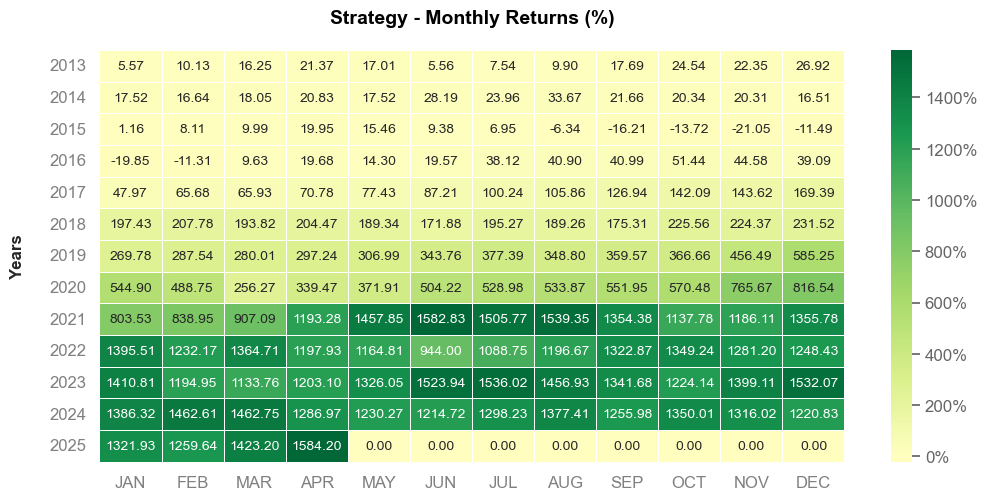

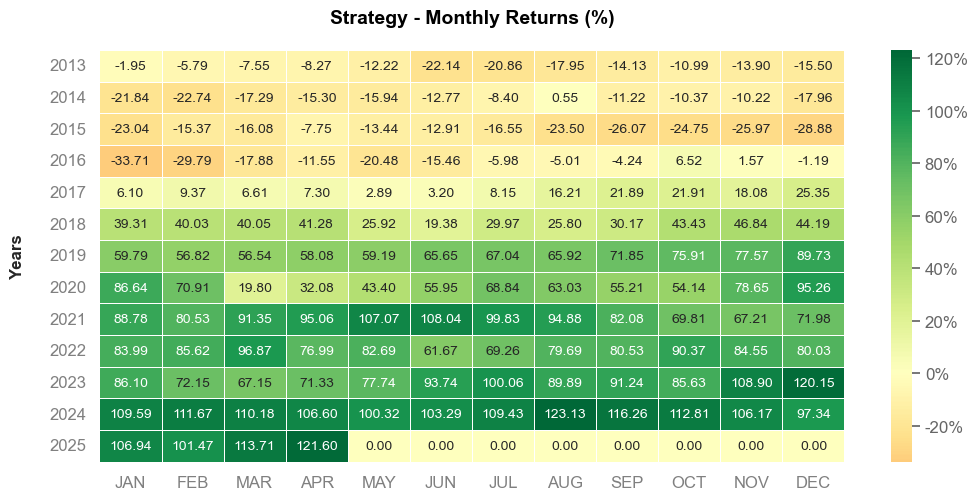

In [20]:
rentabilidade_por_carteiras["estrategia_small_caps"].plot_monthly_heatmap()
rentabilidade_por_carteiras["ibovespa"].plot_monthly_heatmap()

# Passo 11 - Testar outros indicadores